# Step 1: Import Libraries and Load the Iris Dataset

In [ ]:
# This cell loads the Iris dataset from the UCI Machine Learning Repository and isolates two flower species (Setosa and Versicolor) along with two features (sepal length and petal length)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Iris dataset from UCI repository
df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data', header=None)

# Select setosa and versicolor classes
y = df.iloc[0:100, 4].values
y = np.where(y == 'Iris-setosa', -1, 1)

# Select sepal length and petal length features
X = df.iloc[0:100, [0, 2]].values

print(f"Dataset shape: {X.shape}")
print(f"Class labels: {np.unique(y)}")

Dataset shape: (100, 2)
Class labels: [-1  1]


# Implement and Train Frank Rosenblatt's Perceptron

In [ ]:
# This cell defines the Perceptron class using the unit step function and trains it on the Iris dataset

In [2]:
class Perceptron(object):
    def __init__(self, eta=0.01, epochs=50):
        self.eta = eta
        self.epochs = epochs

    def train(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[1:] += update * xi
                self.w_[0] += update
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

# Train Perceptron
ppn = Perceptron(epochs=10, eta=0.1)
ppn.train(X, y)
print('Trained Weights: %s' % ppn.w_)

Trained Weights: [-0.4  -0.68  1.82]


# Visualize Perceptron Decision Regions & Convergence

In [ ]:
# This cell plots the decision boundary and the convergence of misclassifications over iterations.

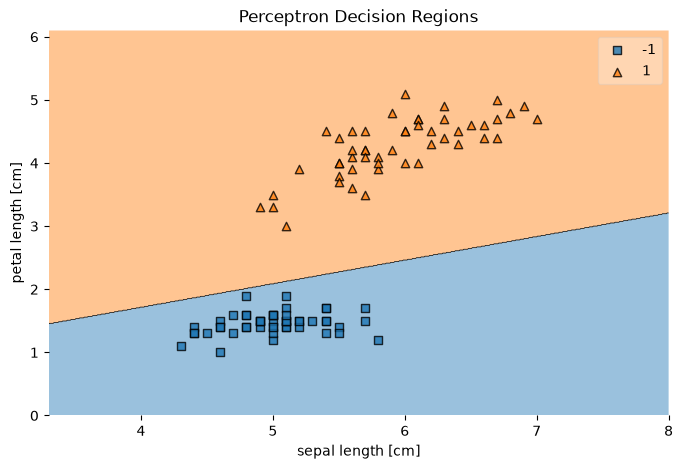

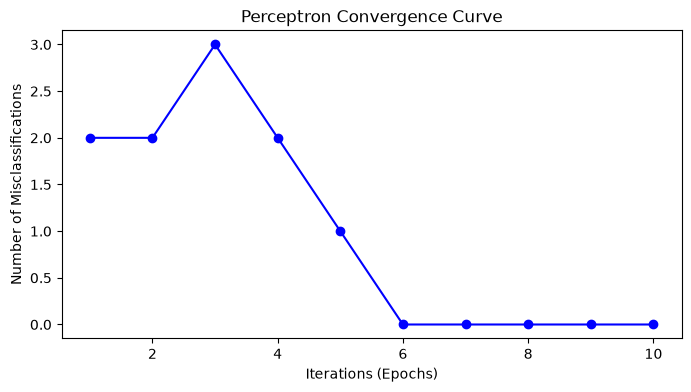

In [3]:
%matplotlib inline
from mlxtend.plotting import plot_decision_regions

# Plot decision boundaries
plt.figure(figsize=(8, 5))
plot_decision_regions(X, y, clf=ppn)
plt.title('Perceptron Decision Regions')
plt.xlabel('sepal length [cm]')
plt.ylabel('petal length [cm]')
plt.show()

# Plot misclassifications per epoch/iteration
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker='o', color='b')
plt.xlabel('Iterations (Epochs)')
plt.ylabel('Number of Misclassifications')
plt.title('Perceptron Convergence Curve')
plt.show()

# Step 4: Implement Adaptive Linear Neurons (Adaline with Batch Gradient Descent)

In [ ]:
# This cell implements Adaline using a continuous linear activation function and the Sum of Squared Errors (SSE) cost function minimized via batch gradient descent

In [4]:
class AdalineGD(object):
    def __init__(self, eta=0.01, epochs=50): 
        self.eta = eta
        self.epochs = epochs

    def train(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.cost_ = []

        for i in range(self.epochs):
            output = self.net_input(X)
            errors = (y - output)
            self.w_[1:] += self.eta * X.T.dot(errors)
            self.w_[0] += self.eta * errors.sum()
            cost = (errors**2).sum() / 2.0
            self.cost_.append(cost)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def activation(self, X):
        return self.net_input(X)

    def predict(self, X):
        return np.where(self.activation(X) >= 0.0, 1, -1)

# Step 5: Feature Standardization & Training Adaline

In [ ]:
# This cell standardizes the feature variables (mean = 0, variance = 1) to ensure proper convergence of gradient descent, then trains Adaline

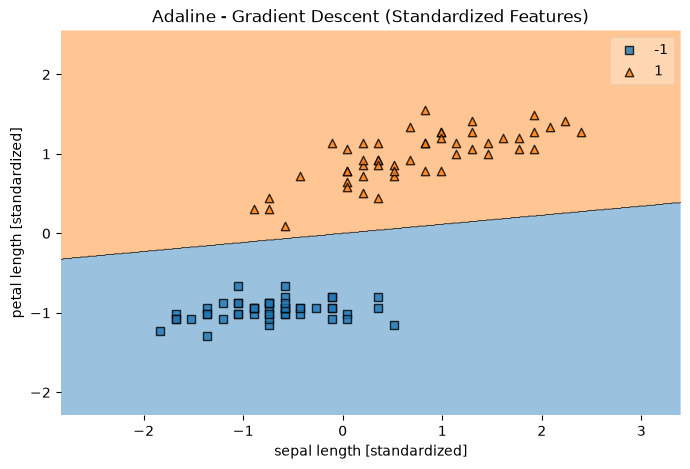

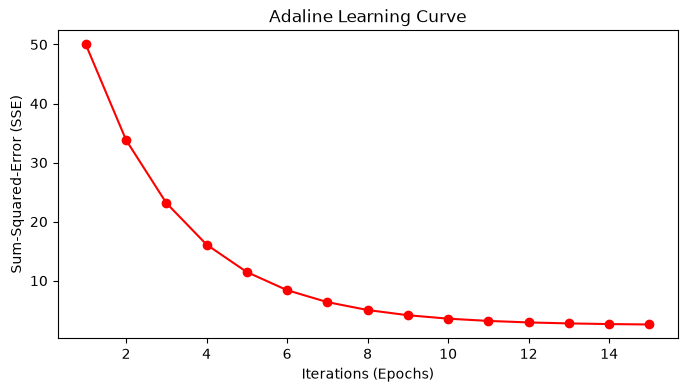

In [5]:
# Standardize features (mean=0, std=1)
X_std = np.copy(X)
X_std[:, 0] = (X[:, 0] - X[:, 0].mean()) / X[:, 0].std()
X_std[:, 1] = (X[:, 1] - X[:, 1].mean()) / X[:, 1].std()

# Train Adaline with standardized features
ada = AdalineGD(epochs=15, eta=0.01)
ada.train(X_std, y)

# Plot Adaline decision regions
plt.figure(figsize=(8, 5))
plot_decision_regions(X_std, y, clf=ada)
plt.title('Adaline - Gradient Descent (Standardized Features)')
plt.xlabel('sepal length [standardized]')
plt.ylabel('petal length [standardized]')
plt.show()

# Plot Cost Function (Sum-squared-error) over epochs
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(ada.cost_) + 1), ada.cost_, marker='o', color='r')
plt.xlabel('Iterations (Epochs)')
plt.ylabel('Sum-Squared-Error (SSE)')
plt.title('Adaline Learning Curve')
plt.show()

# Step 6: Evaluation Metrics (Accuracy, Precision, Recall, F1-Score)

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Predictions
ppn_pred = ppn.predict(X)
ada_pred = ada.predict(X_std)

# Compile evaluation metrics into a summary DataFrame
evaluation_df = pd.DataFrame({
    "Model": ["Perceptron", "Adaline (GD)"],
    "Accuracy": [accuracy_score(y, ppn_pred), accuracy_score(y, ada_pred)],
    "Precision": [precision_score(y, ppn_pred), precision_score(y, ada_pred)],
    "Recall": [recall_score(y, ppn_pred), recall_score(y, ada_pred)],
    "F1-Score": [f1_score(y, ppn_pred), f1_score(y, ada_pred)]
})

display(evaluation_df.style.background_gradient(cmap='Blues', subset=['Accuracy', 'F1-Score']))

,Model,Accuracy,Precision,Recall,F1-Score
0,Perceptron,1.000000,1.000000,1.000000,1.000000
1,Adaline (GD),1.000000,1.000000,1.000000,1.000000


# Step 7: Plotting Training Convergence & Cost Curves

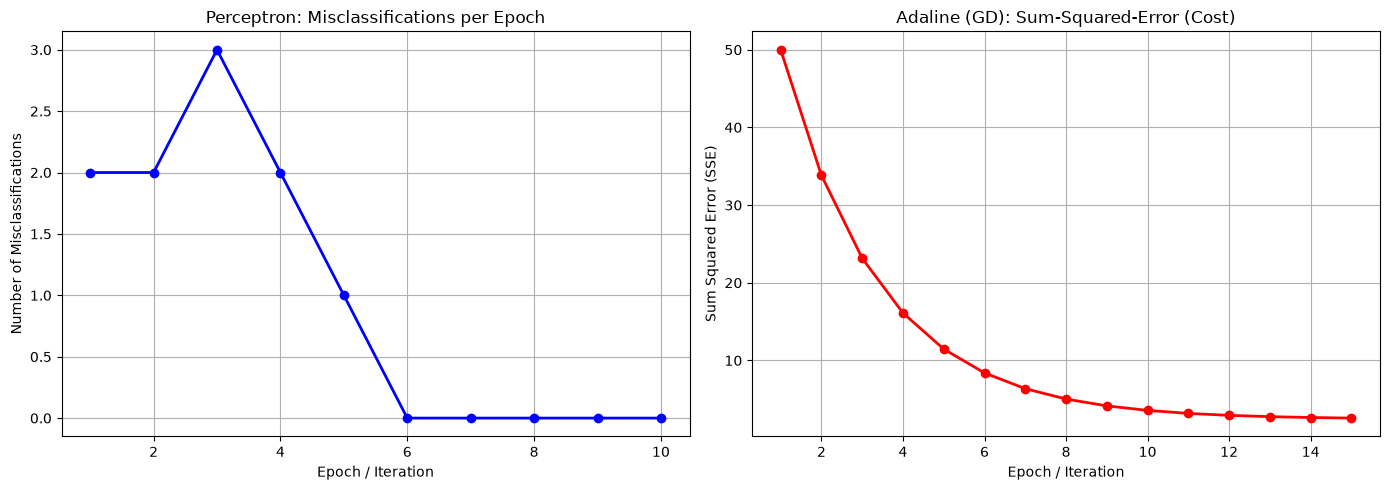

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Perceptron Convergence Curve
axes[0].plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker='o', color='blue', linewidth=2)
axes[0].set_title('Perceptron: Misclassifications per Epoch')
axes[0].set_xlabel('Epoch / Iteration')
axes[0].set_ylabel('Number of Misclassifications')
axes[0].grid(True)

# Adaline Cost Curve (Gradient Descent)
axes[1].plot(range(1, len(ada.cost_) + 1), ada.cost_, marker='o', color='red', linewidth=2)
axes[1].set_title('Adaline (GD): Sum-Squared-Error (Cost)')
axes[1].set_xlabel('Epoch / Iteration')
axes[1].set_ylabel('Sum Squared Error (SSE)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

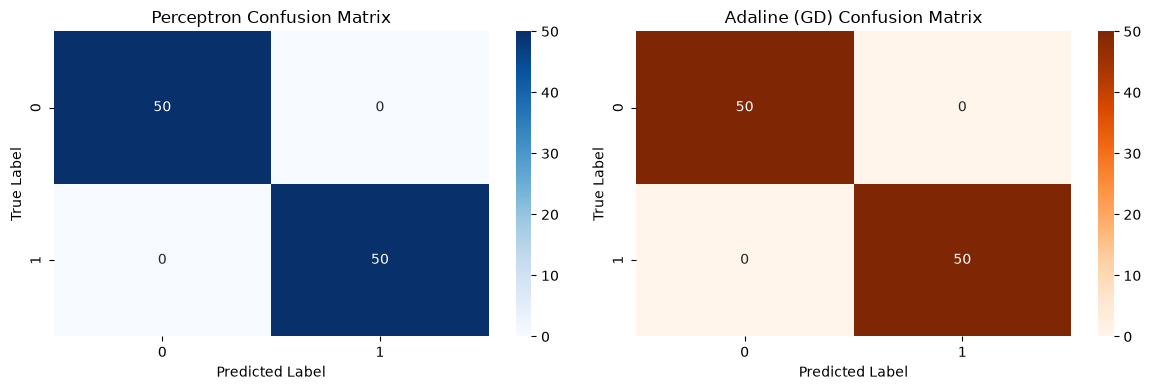

In [8]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Perceptron Confusion Matrix
sns.heatmap(confusion_matrix(y, ppn_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Perceptron Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Adaline Confusion Matrix
sns.heatmap(confusion_matrix(y, ada_pred), annot=True, fmt='d', cmap='Oranges', ax=axes[1])
axes[1].set_title('Adaline (GD) Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()